<a href="https://colab.research.google.com/github/25523264-ux/fsd_Linear_kelompok3/blob/main/B_logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub
import os

path = kagglehub.dataset_download("abcsds/pokemon")
print(path)
print(os.listdir(path))

Using Colab cache for faster access to the 'pokemon' dataset.
/kaggle/input/pokemon
['Pokemon.csv']


In [2]:
import pandas as pd

df = pd.read_csv(os.path.join(path, "Pokemon.csv"))
print(df.shape)
print(df.columns.tolist())
df.head()

(800, 13)
['#', 'Name', 'Type 1', 'Type 2', 'Total', 'HP', 'Attack', 'Defense', 'Sp. Atk', 'Sp. Def', 'Speed', 'Generation', 'Legendary']


,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
4,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False


In [3]:
df.info()
print(df["Legendary"].value_counts())
print(df["Legendary"].value_counts(normalize=True) * 100)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   #           800 non-null    int64 
 1   Name        800 non-null    object
 2   Type 1      800 non-null    object
 3   Type 2      414 non-null    object
 4   Total       800 non-null    int64 
 5   HP          800 non-null    int64 
 6   Attack      800 non-null    int64 
 7   Defense     800 non-null    int64 
 8   Sp. Atk     800 non-null    int64 
 9   Sp. Def     800 non-null    int64 
 10  Speed       800 non-null    int64 
 11  Generation  800 non-null    int64 
 12  Legendary   800 non-null    bool  
dtypes: bool(1), int64(9), object(3)
memory usage: 75.9+ KB
Legendary
False    735
True      65
Name: count, dtype: int64
Legendary
False    91.875
True      8.125
Name: proportion, dtype: float64


## B2 Eksplorasi dan Visualisasi Data

In [4]:
df.describe()

,#,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation
count,800.000000,800.00000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.00000
mean,362.813750,435.10250,69.258750,79.001250,73.842500,72.820000,71.902500,68.277500,3.32375
std,208.343798,119.96304,25.534669,32.457366,31.183501,32.722294,27.828916,29.060474,1.66129
min,1.000000,180.00000,1.000000,5.000000,5.000000,10.000000,20.000000,5.000000,1.00000
25%,184.750000,330.00000,50.000000,55.000000,50.000000,49.750000,50.000000,45.000000,2.00000
50%,364.500000,450.00000,65.000000,75.000000,70.000000,65.000000,70.000000,65.000000,3.00000
75%,539.250000,515.00000,80.000000,100.000000,90.000000,95.000000,90.000000,90.000000,5.00000
max,721.000000,780.00000,255.000000,190.000000,230.000000,194.000000,230.000000,180.000000,6.00000


Melihat gambaran angka datanya: rata-rata, nilai terkecil dan terbesar, sebarannya. Dari sini ketahuan ada nilai ekstrem (outlier) atau tidak.

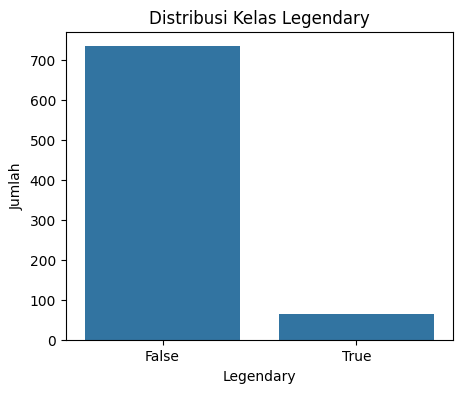

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(5, 4))
sns.countplot(x="Legendary", data=df)
plt.title("Distribusi Kelas Legendary")
plt.xlabel("Legendary")
plt.ylabel("Jumlah")
plt.show()

Melihat seimbang atau tidak jumlah Legendary dan non-Legendary. Hasilnya sangat tidak seimbang (735 vs 65), jadi nanti butuh penanganan khusus.

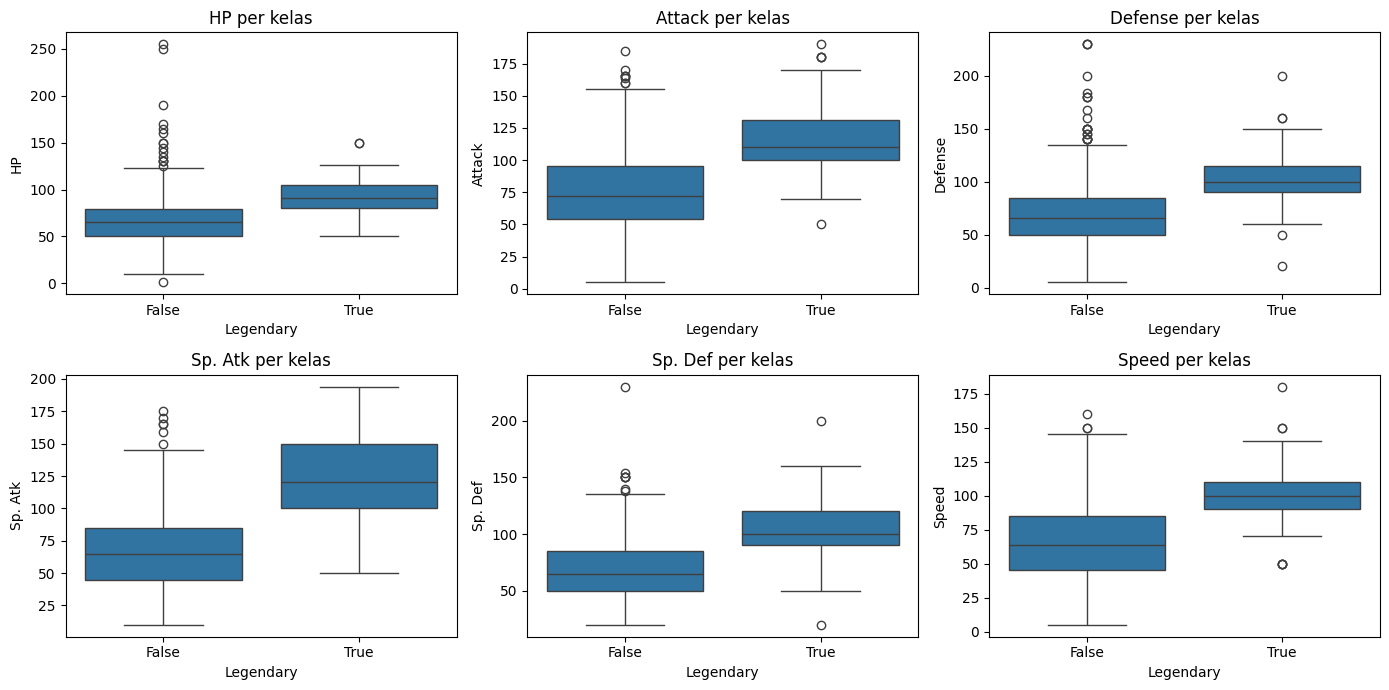

In [6]:
fitur = ["HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, f in zip(axes.ravel(), fitur):
    sns.boxplot(x="Legendary", y=f, data=df, ax=ax)
    ax.set_title(f"{f} per kelas")
plt.tight_layout()
plt.show()

Melihat apakah statistik Pokémon Legendary beda dari yang biasa. Hasilnya beda jelas: Legendary lebih tinggi di semua statistik. Artinya fitur-fitur ini berguna untuk menebak Legendary.

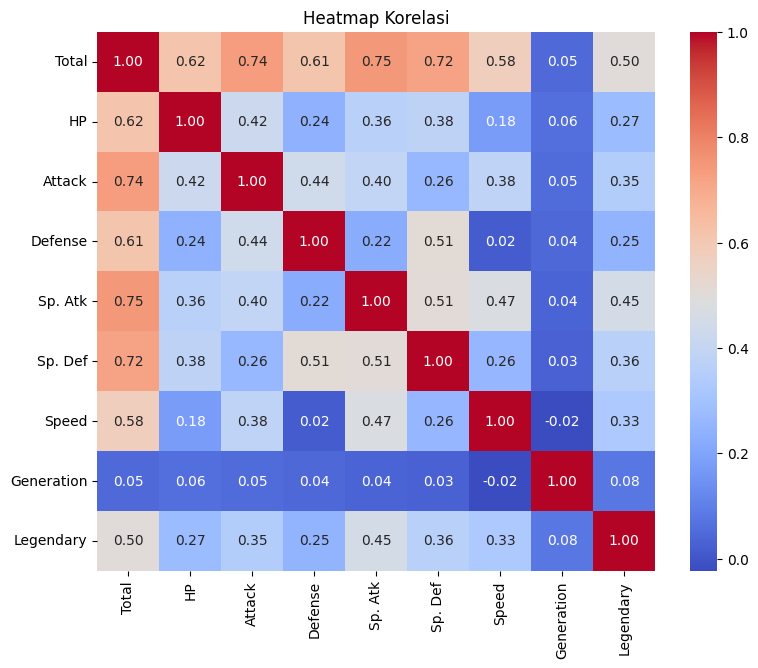

In [7]:
num = df[["Total", "HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed", "Generation"]].copy()
num["Legendary"] = df["Legendary"].astype(int)

plt.figure(figsize=(9, 7))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Heatmap Korelasi")
plt.show()

Melihat fitur mana yang berhubungan dengan fitur lain dan dengan target.

## B3 Preprocessing

In [8]:
print("Missing values:")
print(df.isnull().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())
print("Jumlah nomor # duplikat (bentuk Mega, dll.):", df["#"].duplicated().sum())

Missing values:
#               0
Name            0
Type 1          0
Type 2        386
Total           0
HP              0
Attack          0
Defense         0
Sp. Atk         0
Sp. Def         0
Speed           0
Generation      0
Legendary       0
dtype: int64

Jumlah baris duplikat: 0
Jumlah nomor # duplikat (bentuk Mega, dll.): 79


memeriksa apakah ada data kosong atau data kembar. Kalau ada, model bisa error atau belajar dari data yang salah.

In [9]:
df["Type 2"] = df["Type 2"].fillna("None")
df["Legendary"] = df["Legendary"].astype(int)
print(df["Type 2"].isnull().sum())
print(df["Legendary"].value_counts())

0
Legendary
0    735
1     65
Name: count, dtype: int64


fillna("None") mengisi kekosongan Type 2 dengan tulisan “None”, karena kosong di sini artinya Pokémon itu memang tidak punya tipe kedua, bukan data hilang. Jadi barisnya tidak perlu dibuang.

astype(int) mengubah True/False menjadi 1/0, karena Logistic Regression butuh target berupa angka.
Dua print di bawah hanya untuk memastikan hasilnya benar: kosong sudah 0, dan jumlah kelas tetap 735 dan 65.

In [10]:
fitur = ["HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed"]
for f in fitur:
    q1, q3 = df[f].quantile(0.25), df[f].quantile(0.75)
    iqr = q3 - q1
    n = ((df[f] < q1 - 1.5 * iqr) | (df[f] > q3 + 1.5 * iqr)).sum()
    print(f"{f}: {n} outlier")

HP: 19 outlier
Attack: 7 outlier
Defense: 13 outlier
Sp. Atk: 10 outlier
Sp. Def: 7 outlier
Speed: 2 outlier


menghitung berapa banyak nilai ekstrem di tiap fitur, supaya keputusan “outlier dipertahankan” punya angka sebagai dasar.

## B4 Pemilihan Fitur

In [11]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

def hitung_vif(kolom):
    X_v = add_constant(df[kolom])
    return pd.DataFrame({
        "fitur": X_v.columns,
        "VIF": [variance_inflation_factor(X_v.values, i) for i in range(X_v.shape[1])]
    })

print("Dengan Total:")
display(hitung_vif(["Total", "HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed"]))

print("Tanpa Total:")
display(hitung_vif(["HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed"]))

Dengan Total:


/tmp/ipykernel_2132/4137888019.py:8: UserWarning: The design matrix is poorly conditioned (condition number=7.43e+15). VIF calculations may be numerically unstable.
  "VIF": [variance_inflation_factor(X_v.values, i) for i in range(X_v.shape[1])]
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


,fitur,VIF
0,const,1.000000e+00
1,Total,1.000800e+15
2,HP,1.000800e+15
3,Attack,1.000800e+15
4,Defense,1.000800e+15
5,Sp. Atk,1.000800e+15
6,Sp. Def,1.000800e+15
7,Speed,1.000800e+15


Tanpa Total:


,fitur,VIF
0,const,1.000000
1,HP,1.380728
2,Attack,1.784860
3,Defense,1.747821
4,Sp. Atk,1.730937
5,Sp. Def,1.908071
6,Speed,1.480180


membuktikan dengan angka bahwa Total bermasalah. VIF mengukur seberapa besar sebuah fitur bisa “ditebak” dari fitur lain. Aturan umumnya, VIF di atas 5 sampai 10 berarti multikolinearitas tinggi.

In [12]:
from sklearn.feature_selection import SelectKBest, f_classif, chi2

num_cols = ["HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed", "Generation"]
sk = SelectKBest(score_func=f_classif, k="all").fit(df[num_cols], df["Legendary"])

hasil_num = pd.DataFrame({
    "fitur": num_cols,
    "F-score": sk.scores_,
    "p-value": sk.pvalues_
}).sort_values("F-score", ascending=False)
hasil_num

,fitur,F-score,p-value
3,Sp. Atk,201.396010,6.314916e-41
4,Sp. Def,121.831948,1.843981e-26
1,Attack,108.104284,7.827253e-24
5,Speed,95.359802,2.354075e-21
0,HP,64.579295,3.330648e-15
2,Defense,51.570210,1.584223e-12
6,Generation,5.113437,2.400968e-02


meranking fitur numerik berdasarkan seberapa berbeda nilainya antara kelas Legendary dan non-Legendary.

In [13]:
cat = pd.get_dummies(df[["Type 1", "Type 2"]]).astype(int)
ch = SelectKBest(score_func=chi2, k="all").fit(cat, df["Legendary"])

hasil_cat = pd.DataFrame({
    "fitur": cat.columns,
    "chi2": ch.scores_,
    "p-value": ch.pvalues_
}).sort_values("chi2", ascending=False)
hasil_cat.head(10)

,fitur,chi2,p-value
2,Type 1_Dragon,36.990058,1.187331e-09
14,Type 1_Psychic,20.628503,5.575974e-06
7,Type 1_Flying,9.396128,2.174442e-03
0,Type 1_Bug,6.102041,1.350259e-02
12,Type 1_Normal,4.859706,2.749102e-02
20,Type 2_Dragon,4.792023,2.859183e-02
24,Type 2_Fire,4.577708,3.239051e-02
25,Type 2_Flying,3.618557,5.713842e-02
29,Type 2_Ice,3.319279,6.847184e-02
17,Type 1_Water,3.111011,7.776466e-02


mengecek apakah jenis tipe Pokémon berkaitan dengan status Legendary.

In [14]:
fitur_num = ["HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed"]

X = pd.concat([
    df[fitur_num],
    pd.get_dummies(df[["Type 1", "Type 2"]], drop_first=True).astype(int)
], axis=1)
y = df["Legendary"]

print(X.shape)
print(y.shape)
X.head()

(800, 41)
(800,)


,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Type 1_Dark,Type 1_Dragon,Type 1_Electric,Type 1_Fairy,...,Type 2_Grass,Type 2_Ground,Type 2_Ice,Type 2_None,Type 2_Normal,Type 2_Poison,Type 2_Psychic,Type 2_Rock,Type 2_Steel,Type 2_Water
0,45,49,49,65,65,45,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
1,60,62,63,80,80,60,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,80,82,83,100,100,80,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,80,100,123,122,120,80,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
4,39,52,43,60,50,65,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0


membentuk tabel fitur X dan target y dari hasil keputusan di atas

## B5 Pembagian Data

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("\nProporsi Legendary di data latih:", round(y_train.mean() * 100, 2), "%")
print("Proporsi Legendary di data uji:", round(y_test.mean() * 100, 2), "%")

Data latih: (640, 41) | Data uji: (160, 41)

Proporsi Legendary di data latih: 8.12 %
Proporsi Legendary di data uji: 8.12 %


memisahkan 80% data untuk melatih model dan 20% untuk menguji, supaya kita tahu performa model pada data yang belum pernah dilihat.

In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = X_train.copy()
X_test_s = X_test.copy()

X_train_s[fitur_num] = scaler.fit_transform(X_train[fitur_num])
X_test_s[fitur_num] = scaler.transform(X_test[fitur_num])

X_train_s.head()

,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Type 1_Dark,Type 1_Dragon,Type 1_Electric,Type 1_Fairy,...,Type 2_Grass,Type 2_Ground,Type 2_Ice,Type 2_None,Type 2_Normal,Type 2_Poison,Type 2_Psychic,Type 2_Rock,Type 2_Steel,Type 2_Water
452,-0.357180,-0.290964,-0.269019,1.631034,1.177901,0.750109,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
574,-0.757382,-0.807812,-0.832323,-0.608612,-0.845637,-0.149351,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
673,0.283143,2.050052,0.559369,-0.390869,-0.064622,0.992271,0,1,0,0,...,0,0,0,1,0,0,0,0,0,0
276,-0.957483,-0.594992,-1.097408,-0.079807,-0.774636,-0.806649,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
75,-0.757382,-0.138950,-1.263085,-0.079807,-1.484649,-0.979623,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0


menyamakan skala fitur numerik (rata-rata 0, standar deviasi 1) supaya model stabil dan koefisiennya bisa dibandingkan antar fitur.

Data dibagi 80:20 dengan `stratify=y` agar proporsi kelas Legendary (sekitar 8%) tetap terjaga di data latih maupun data uji, dan `random_state=42` agar hasil dapat direproduksi. Scaling dengan `StandardScaler` dilakukan setelah pembagian: scaler hanya dilatih pada data latih, lalu diterapkan ke data uji, untuk mencegah kebocoran data.

## B6 Pemodelan

In [17]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
model.fit(X_train_s, y_train)

print("Intercept:", model.intercept_[0])

Intercept: -7.330101625886324


melatih Logistic Regression untuk menebak Legendary atau bukan.

In [18]:
import numpy as np

koef = pd.DataFrame({
    "fitur": X_train_s.columns,
    "koefisien": model.coef_[0],
    "odds_ratio": np.exp(model.coef_[0])
}).sort_values("koefisien", ascending=False)

koef

,fitur,koefisien,odds_ratio
5,Speed,1.923452,6.844547
4,Sp. Def,1.722466,5.598315
3,Sp. Atk,1.600480,4.955412
0,HP,1.475841,4.374716
19,Type 1_Psychic,1.458203,4.298227
2,Defense,1.139718,3.125886
40,Type 2_Water,1.071391,2.919437
34,Type 2_None,1.052502,2.864809
12,Type 1_Flying,1.016797,2.764328
15,Type 1_Ground,0.831363,2.296446


melihat seberapa besar pengaruh tiap fitur terhadap peluang menjadi Legendary.

## B7. Evaluasi

In [19]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

y_pred = model.predict(X_test_s)
y_proba = model.predict_proba(X_test_s)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("F1-score :", round(f1_score(y_test, y_pred), 3))
print()
print(classification_report(y_test, y_pred, target_names=["Non-Legendary", "Legendary"]))

Accuracy : 0.9
Precision: 0.44
Recall   : 0.846
F1-score : 0.579

               precision    recall  f1-score   support

Non-Legendary       0.99      0.90      0.94       147
    Legendary       0.44      0.85      0.58        13

     accuracy                           0.90       160
    macro avg       0.71      0.88      0.76       160
 weighted avg       0.94      0.90      0.91       160



menilai seberapa baik model pada data uji (data yang belum pernah dilihat).

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
print(cm)

ConfusionMatrixDisplay(cm, display_labels=["Non-Legendary", "Legendary"]).plot(cmap="Blues")
plt.title("Confusion Matrix (Data Uji)")
plt.show()

[[133  14]
 [  2  11]]


melihat jenis kesalahan model secara rinci.

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, _ = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Tebakan acak")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("Kurva ROC")
plt.legend()
plt.show()

print("AUC:", round(auc, 3))

menilai kemampuan model membedakan kedua kelas di semua ambang batas peluang, bukan hanya di ambang 0,5.

In [ ]:
import numpy as np

print("=== B3: duplikat dan outlier (IQR) ===")
print("Duplikat penuh:", df.duplicated().sum())
for f in fitur_num:
    q1, q3 = df[f].quantile(0.25), df[f].quantile(0.75)
    iqr = q3 - q1
    n = ((df[f] < q1 - 1.5 * iqr) | (df[f] > q3 + 1.5 * iqr)).sum()
    print(f"{f}: {n} outlier")

print("\n=== B4: VIF ===")
vt = hitung_vif(["Total"] + fitur_num)
print("VIF dengan Total:")
print(vt.round(1).to_string(index=False))
v = hitung_vif(fitur_num)
print("VIF tanpa Total:")
print(v[v.fitur != "const"].round(1).to_string(index=False))

print("\n=== B4: F-test fitur numerik ===")
print(hasil_num.round(3).to_string(index=False))
print("\n=== B4: chi-square tipe (5 teratas) ===")
print(hasil_cat.head(5).round(3).to_string(index=False))
print("\nJumlah kolom fitur akhir:", X.shape[1])
print("Kolom:", X.columns.tolist())

print("\n=== B5: proporsi kelas ===")
print("Legendary latih:", int(y_train.sum()), "| uji:", int(y_test.sum()))

print("\n=== B6: koefisien ===")
print("Intercept:", round(model.intercept_[0], 3))
print(koef.round(3).head(6).to_string(index=False))
print("...")
print(koef.round(3).tail(3).to_string(index=False))